# 03 Explore

Now that we know which 726 series we study, we look at them before fitting anything: how big they are, how often
they are zero, how they move through the week and the year, and what moves with them (price, SNAP days, events).
We also check for missing days and extreme values. What we see here decides which models make sense later.

## Load

In [1]:
import sys
sys.path.append("../src")
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from config import ROOT, RAW, INTERIM, TABLES, FIGS, CATEGORIES, FIG_STYLE
from stationarity import count_outliers, outlier_cut
from break_detection import weekly_ca_prices

plt.rcParams.update(FIG_STYLE)
written = []

df = pd.concat([pd.read_csv(INTERIM / f"{c}_candidates.csv", parse_dates=["date"])
                for c in ["foods", "hobbies", "household"]], ignore_index=True)
df["category"] = df["item_id"].str.split("_").str[0]
cal = pd.read_csv(RAW / "calendar.csv", parse_dates=["date"])
df = df.merge(cal[["date", "weekday", "month", "snap_CA", "event_name_1"]], on="date", how="left")
print(df["item_id"].nunique(), "products,", f"{len(df):,} product-days")

726 products, 1,290,010 product-days


## Summary statistics

In [2]:
per_item = df.groupby(["item_id", "category"])["sales"].agg(mean="mean", median="median", sd="std",
                                                            zero_share=lambda s: (s == 0).mean()).reset_index()
per_item["cv"] = per_item["sd"] / per_item["mean"]
table = per_item.groupby("category")[["mean", "median", "sd", "cv", "zero_share"]].median()
table.loc["ALL"] = per_item[["mean", "median", "sd", "cv", "zero_share"]].median()
print("median over products of each product's daily statistic:")
table.round(3)

median over products of each product's daily statistic:


,mean,median,sd,cv,zero_share
category,,,,,
FOODS,14.412,13.0,9.260,0.657,0.062
HOBBIES,5.338,5.0,3.734,0.732,0.088
HOUSEHOLD,6.672,6.0,4.211,0.648,0.058
ALL,9.978,9.0,6.396,0.667,0.062


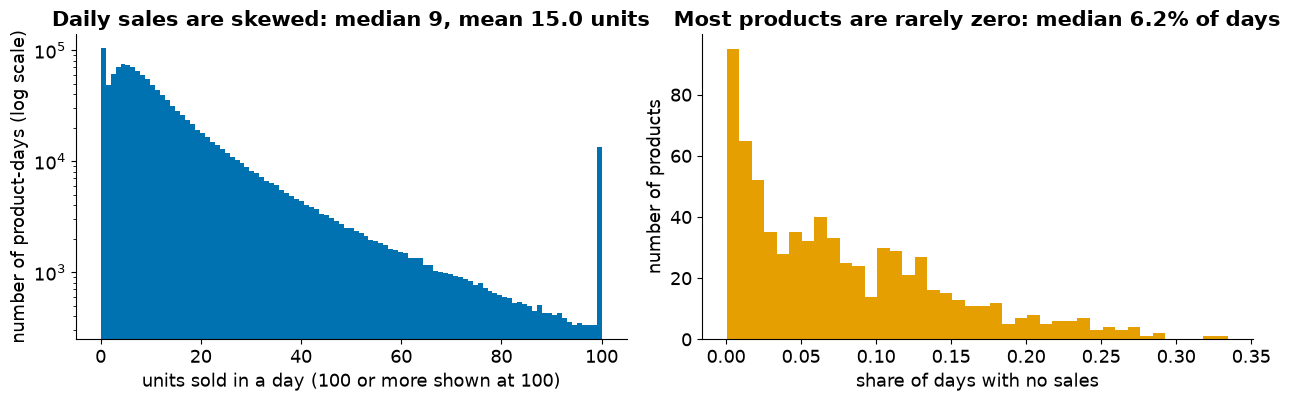

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(df["sales"].clip(upper=100), bins=101, color="#0072B2")
axes[0].set_yscale("log")
axes[0].set_title(f"Daily sales are skewed: median {df['sales'].median():.0f}, mean {df['sales'].mean():.1f} units")
axes[0].set_xlabel("units sold in a day (100 or more shown at 100)")
axes[0].set_ylabel("number of product-days (log scale)")
axes[1].hist(per_item["zero_share"], bins=40, color="#E69F00")
axes[1].set_title(f"Most products are rarely zero: median {per_item['zero_share'].median():.1%} of days")
axes[1].set_xlabel("share of days with no sales")
axes[1].set_ylabel("number of products")
fig.tight_layout()
fig.savefig(FIGS / "sales_and_zero_share_histograms.png")
written.append(FIGS / "sales_and_zero_share_histograms.png")
plt.show()

## Line plots

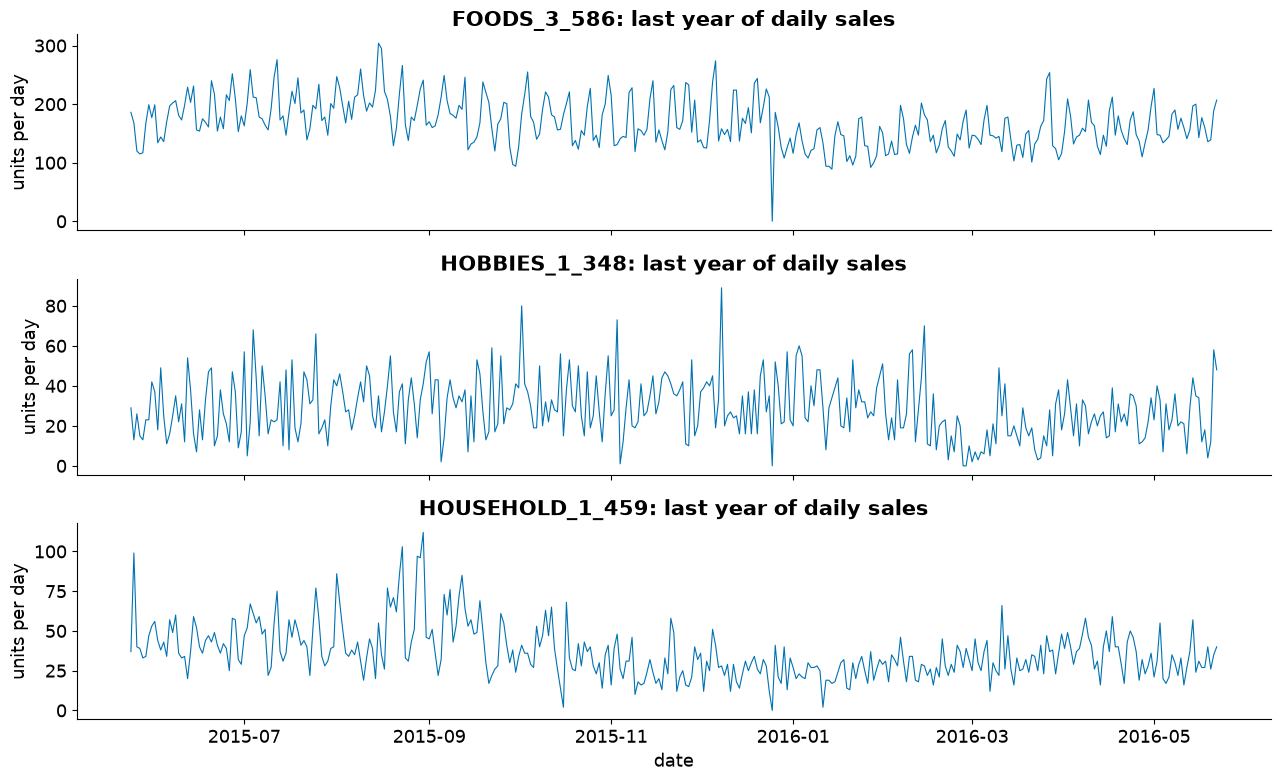

In [4]:
picks = ["FOODS_3_586", "HOBBIES_1_348", "HOUSEHOLD_1_459"]
picks = [p if p in set(df["item_id"]) else df[df["category"] == p.split("_")[0]]["item_id"].iloc[0] for p in picks]
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
for ax, item in zip(axes, picks):
    ts = df[df["item_id"] == item].set_index("date")["sales"].iloc[-365:]
    ax.plot(ts.index, ts, lw=0.8, color="#0072B2")
    ax.set_title(f"{item}: last year of daily sales")
    ax.set_ylabel("units per day")
axes[-1].set_xlabel("date")
fig.tight_layout()
fig.savefig(FIGS / "daily_line_three_products.png")
written.append(FIGS / "daily_line_three_products.png")
plt.show()

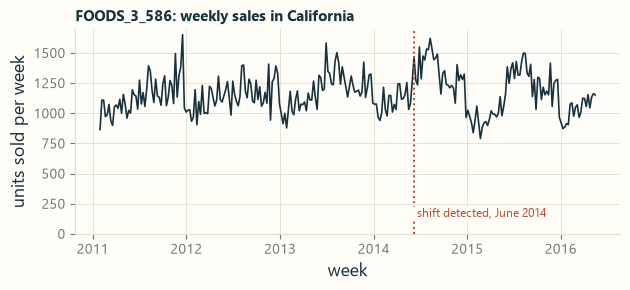

277 full weeks; the June 2014 line marks the shift found in 08a_break_detection


In [5]:
# weekly totals of one steady best seller over the whole period
from plots import CREAM, INK, ACCENT, PAPER
item = "FOODS_3_586"
ts = df[df["item_id"] == item].copy()
ts["week"] = ts["date"] - pd.to_timedelta((ts["date"].dt.dayofweek - 5) % 7, unit="D")
wk = ts.groupby("week")["sales"].agg(["sum", "size"])
wk = wk[wk["size"] == 7]["sum"]
with plt.rc_context(CREAM):
    fig, ax = plt.subplots(figsize=(6.4, 3.0))
    ax.plot(wk.index, wk, color=INK, lw=1.2)
    brk = pd.Timestamp("2014-06-07")
    ax.axvline(brk, color=ACCENT, ls=":", lw=1.4)
    ax.text(brk, 120, " shift detected, June 2014", color=ACCENT, fontsize=8.5, va="bottom",
            bbox=dict(facecolor=PAPER, edgecolor="none", pad=1))
    ax.set_ylabel("units sold per week")
    ax.set_xlabel("week")
    ax.set_title(f"{item}: weekly sales in California", loc="left", fontsize=11, fontweight="bold")
    ax.set_ylim(bottom=0)
    fig.tight_layout()
    fig.savefig(FIGS / "plot_line_one_product.png", dpi=200)
    plt.show()
written.append(FIGS / "plot_line_one_product.png")
print(f"{len(wk)} full weeks; the June 2014 line marks the shift found in 08a_break_detection")

## Seasonal plots: by weekday, by month, by category

In [6]:
tot = df.groupby(["date", "category"])["sales"].sum().unstack()
tot = tot.join(cal.set_index("date")[["weekday", "month", "snap_CA", "event_name_1"]])
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = 100 * tot.groupby("weekday")[CATEGORIES].mean().loc[order] / tot[CATEGORIES].mean()
by_month = 100 * tot.groupby("month")[CATEGORIES].mean() / tot[CATEGORIES].mean()
print("weekday index (100 = average day):")
print(by_day.round(1))
print("\nmonth index:")
print(by_month.round(1).T)

weekday index (100 = average day):
           FOODS  HOBBIES  HOUSEHOLD
weekday                             
Monday      96.7     95.1       97.5
Tuesday     88.0     91.7       86.7
Wednesday   85.9     90.7       83.2
Thursday    87.0     90.5       83.1
Friday      98.9    101.7       94.9
Saturday   120.4    120.7      125.6
Sunday     123.0    109.4      128.8

month index:
month        1      2      3      4      5      6      7      8      9   \
FOODS      96.6   94.9   96.5   97.7   97.5  106.0  107.8  109.4  107.2   
HOBBIES    99.4  103.5  100.5  104.7  100.2  108.1  102.9   97.0   92.9   
HOUSEHOLD  93.5   95.2   98.6   99.0   96.6  101.6  104.7  110.4  109.1   

month         10    11    12  
FOODS      100.8  94.1  93.5  
HOBBIES     97.2  95.8  96.4  
HOUSEHOLD  104.9  97.8  90.4  


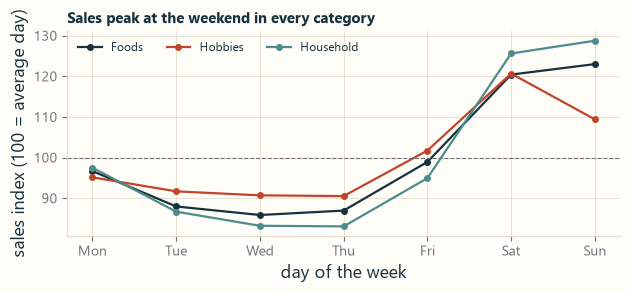

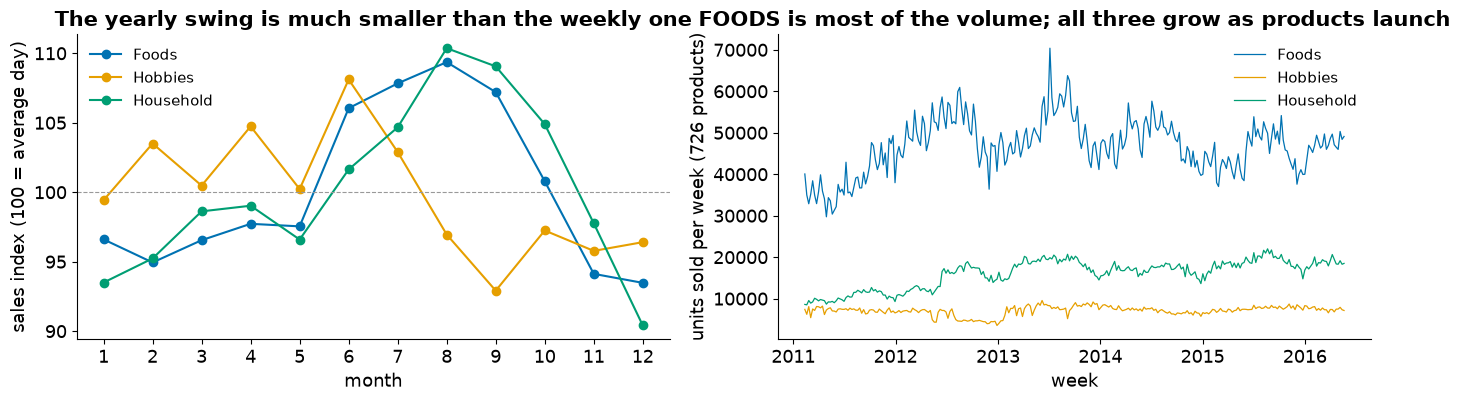

In [7]:
with plt.rc_context(CREAM):
    fig, ax = plt.subplots(figsize=(6.4, 3.0))
    for cat, colour in zip(CATEGORIES, [INK, ACCENT, "#4E8C8C"]):
        ax.plot(range(7), by_day[cat], marker="o", ms=4, lw=1.6, color=colour, label=cat.title())
    ax.axhline(100, color="#6B7378", lw=0.8, ls="--")
    ax.set_xticks(range(7), [d[:3] for d in order])
    ax.set_xlabel("day of the week")
    ax.set_ylabel("sales index (100 = average day)")
    ax.set_title("Sales peak at the weekend in every category", loc="left", fontsize=11, fontweight="bold")
    ax.legend(frameon=False, fontsize=8.5, ncol=3, loc="upper left")
    fig.tight_layout()
    fig.savefig(FIGS / "plot_seasonal_weekday.png", dpi=200)
    plt.show()
written.append(FIGS / "plot_seasonal_weekday.png")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for cat, c in zip(CATEGORIES, ["#0072B2", "#E69F00", "#009E73"]):
    axes[0].plot(by_month.index, by_month[cat], marker="o", color=c, label=cat.title())
axes[0].axhline(100, color="#999999", ls="--", lw=0.8)
axes[0].set_xticks(range(1, 13))
axes[0].set_xlabel("month")
axes[0].set_ylabel("sales index (100 = average day)")
axes[0].set_title("The yearly swing is much smaller than the weekly one")
axes[0].legend(frameon=False)
wk_tot = tot[CATEGORIES].resample("W-FRI").sum().iloc[1:-1]
for cat, c in zip(CATEGORIES, ["#0072B2", "#E69F00", "#009E73"]):
    axes[1].plot(wk_tot.index, wk_tot[cat], color=c, lw=0.9, label=cat.title())
axes[1].set_xlabel("week")
axes[1].set_ylabel("units sold per week (726 products)")
axes[1].set_title("FOODS is most of the volume; all three grow as products launch")
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGS / "seasonal_month_and_category.png")
written.append(FIGS / "seasonal_month_and_category.png")
plt.show()

## What moves with sales: price, SNAP days, events

In [8]:
# SNAP and event days, compared with normal days of the same weekday (weekends would bias a plain average)
rows = []
for cat in CATEGORIES:
    base = tot.groupby("weekday")[cat].transform("mean")
    rel = tot[cat] / base
    normal = tot["event_name_1"].isna()
    rows.append({"category": cat,
                 "snap_vs_other_days": rel[(tot["snap_CA"] == 1) & normal].mean() / rel[(tot["snap_CA"] == 0) & normal].mean() - 1,
                 "event_vs_normal_days": rel[~normal].mean() / rel[normal].mean() - 1,
                 # Christmas is an event, but the stores are closed, so we also look without it
                 "event_vs_normal_no_christmas": rel[~normal & (tot["event_name_1"] != "Christmas")].mean() / rel[normal].mean() - 1})
calendar_effects = pd.DataFrame(rows)
calendar_effects

,category,snap_vs_other_days,event_vs_normal_days,event_vs_normal_no_christmas
0,FOODS,0.100187,-0.047531,-0.016435
1,HOBBIES,0.034796,-0.073305,-0.043021
2,HOUSEHOLD,0.039279,-0.071099,-0.040743


593 products with at least two prices; median Spearman rho -0.15; negative for 68%


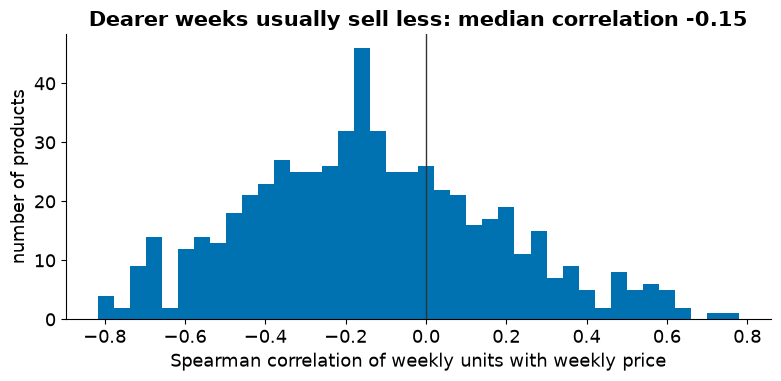

In [9]:
# price: does a product sell less in weeks when it is dearer? (weekly units vs its own weekly median price)
prices = pd.read_csv(RAW / "sell_prices.csv", dtype={"store_id": "category"})
pw = weekly_ca_prices(prices, cal, df["item_id"].unique())
del prices
df["week"] = df["date"] - pd.to_timedelta((df["date"].dt.dayofweek - 5) % 7, unit="D")
wk_sales = df.groupby(["item_id", "week"])["sales"].agg(["sum", "size"]).query("size == 7")["sum"].unstack(0)
rho = {}
for item in wk_sales.columns:
    both = pd.concat([wk_sales[item], pw[item]], axis=1, keys=["units", "price"]).dropna()
    if both["price"].nunique() > 1:
        rho[item] = stats.spearmanr(both["units"], both["price"])[0]
rho = pd.Series(rho)
print(f"{len(rho)} products with at least two prices; median Spearman rho {rho.median():+.2f}; "
      f"negative for {(rho < 0).mean():.0%}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(rho, bins=40, color="#0072B2")
ax.axvline(0, color="#333333", lw=1)
ax.set_xlabel("Spearman correlation of weekly units with weekly price")
ax.set_ylabel("number of products")
ax.set_title(f"Dearer weeks usually sell less: median correlation {rho.median():+.2f}")
fig.tight_layout()
fig.savefig(FIGS / "price_sales_correlation.png")
written.append(FIGS / "price_sales_correlation.png")
plt.show()

## Missing days and extreme values

The raw file has no empty cells, so a "missing value" here can only mean a gap in the dates, or the zeros before a
product's first sale (those get their own notebook next). A day counts as extreme if it is above Q3 + 3 × IQR of
that product's daily sales. We flag those days but never change them: a promotion spike is real demand.

In [10]:
sales = pd.read_csv(RAW / "sales_train_evaluation.csv")
day_cols = [c for c in sales.columns if c.startswith("d_")]
ca_raw = sales[sales["state_id"] == "CA"].groupby("item_id")[day_cols].sum()
ca_raw.columns = cal.set_index("d").loc[day_cols, "date"]
del sales

long_df = df[["item_id", "date", "sales", "category"]]
gaps = long_df.groupby("item_id")["date"].apply(lambda d: (d.diff().dt.days.dropna() != 1).sum())
quality = []
for cat in CATEGORIES + ["ALL"]:
    ids = long_df["item_id"].unique() if cat == "ALL" else long_df.loc[long_df["category"] == cat, "item_id"].unique()
    g = long_df[long_df["item_id"].isin(ids)]
    raw = ca_raw.loc[ids]
    quality.append({"category": cat, "items": len(ids), "raw_empty_cells": int(raw.isna().sum().sum()),
                    "leading_zero_days_trimmed": int(raw.shape[0] * raw.shape[1] - len(g)),
                    "missing_days_inside_series": int(gaps.loc[ids].sum()),
                    "zero_days_kept_share": float((g["sales"] == 0).mean()),
                    "outlier_days": int(sum(count_outliers(x) for _, x in g.groupby("item_id")["sales"])),
                    "days_in_series": len(g)})
quality = pd.DataFrame(quality)
quality["outlier_share"] = quality["outlier_days"] / quality["days_in_series"]
quality.to_csv(TABLES / "data_quality.csv", index=False)
written.append(TABLES / "data_quality.csv")
quality

,category,items,raw_empty_cells,leading_zero_days_trimmed,missing_days_inside_series,zero_days_kept_share,outlier_days,days_in_series,outlier_share
0,FOODS,337,0,44914,0,0.080167,1460,609203,0.002397
1,HOBBIES,106,0,12223,0,0.092191,485,193523,0.002506
2,HOUSEHOLD,283,0,62019,0,0.077567,615,487284,0.001262
3,ALL,726,0,119156,0,0.080989,2560,1290010,0.001984


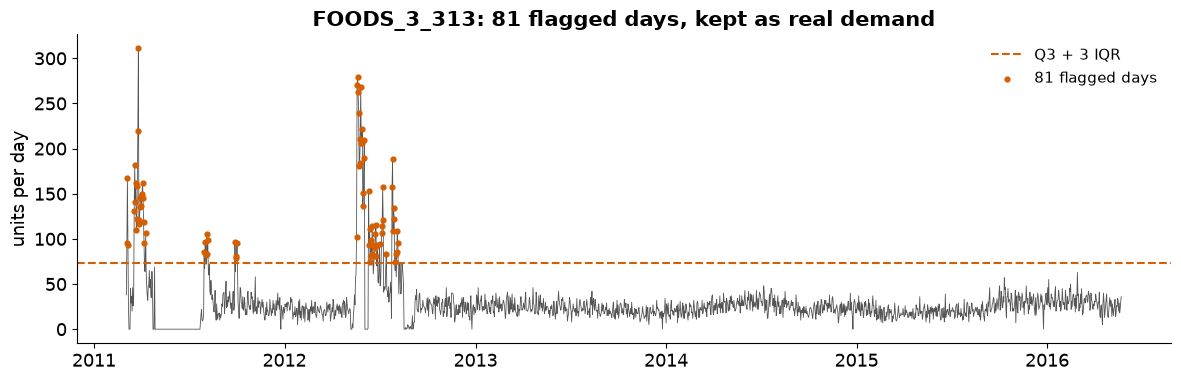

In [11]:
series = {i: g.sort_values("date")["sales"].to_numpy() for i, g in long_df.groupby("item_id")}
n_out = {i: count_outliers(y) for i, y in series.items()}
worst = max(n_out, key=n_out.get)
y = long_df[long_df["item_id"] == worst].set_index("date")["sales"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y.index, y, lw=0.6, color="#555555")
ax.axhline(outlier_cut(y), color="#D55E00", ls="--", label="Q3 + 3 IQR")
hi = y[y > outlier_cut(y)]
ax.scatter(hi.index, hi, color="#D55E00", s=12, zorder=3, label=f"{len(hi)} flagged days")
ax.set_title(f"{worst}: {len(hi)} flagged days, kept as real demand")
ax.set_ylabel("units per day")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGS / "outliers_example.png")
written.append(FIGS / "outliers_example.png")
plt.show()

## What we found

A typical product sells about 10 units a day (median of the product means), FOODS about 14, HOBBIES about 5 and
HOUSEHOLD about 7. Daily sales are skewed: the median product-day is 9 units, but a few days run far higher. The
coefficient of variation sits around 0.67, which is why these products landed in the X and Y groups. Zeros are rare
once we start at the first sale: the median product has no sales on 6.2% of its days.

The week is the strongest rhythm we see. Saturday and Sunday sell 20-29% above an average day in FOODS and
HOUSEHOLD, and the middle of the week is about 12-17% below. HOBBIES peaks on Saturday but drops back on Sunday.
The year matters less: FOODS and HOUSEHOLD are up to about 10% above average in summer (June to September) and
up to 10% below it in December and January. HOBBIES swings about as much but on its own calendar, highest in June and
lowest in September. These monthly averages also carry the growth of the totals over the years, which
06_decomposition separates out; there HOBBIES peaks in December instead. So any model we fit needs a weekly season first; a yearly one is a smaller
second effect.

SNAP days (the 1st to 10th of each month in California) sell about 10% more FOODS than other days of the same
weekday, and about 3-4% more of the other two categories. That fits food-assistance money being spent on food, but
those days are also the start of the month, so we cannot separate SNAP from payday with this check. Event days were
a surprise: they sell slightly less than normal days, not more, even after we leave out Christmas, when the stores
close (FOODS about 2% less, the other two about 4% less).

Price works the way we expected. For 593 products whose price changed at least once, weeks with a higher price
usually sell less: the median correlation is -0.15, negative for 68% of them. It is a weak effect at weekly level.

The data itself is clean. There are no empty cells and no missing days inside any series. 8.1% of kept days are
zero, and 0.2% of days are flagged as extreme; we keep both, because they are real sales.

## What comes next

`04_zeros_and_trimming` looks at the zeros at the start of the series, which we have been cutting off since notebook 02.

In [12]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

outputs\figures\sales_and_zero_share_histograms.png 77 KB
outputs\figures\daily_line_three_products.png 310 KB
outputs\figures\plot_line_one_product.png 96 KB
outputs\figures\plot_seasonal_weekday.png 90 KB
outputs\figures\seasonal_month_and_category.png 213 KB
outputs\figures\price_sales_correlation.png 40 KB
outputs\tables\data_quality.csv 0 KB
outputs\figures\outliers_example.png 104 KB
